# Hopfield exemplar prior and recurrent feature retrieval

This extension compares the original Hamming-kernel exemplar prior with Hebbian Hopfield energy. Both learn from the same training feature configurations. Category labels are unnecessary for either exemplar method. The original renderer and observation model support completion of held-out images.

The notebook also runs a controlled memory task with partial feature cues. Recurrent retrieval updates unknown feature groups, while known feature values stay clamped. We compare the result with the global minimum-energy state and the original exemplar-prior MAP under identical feature constraints.

The feature vocabulary is supplied. Each feature has exactly one selected value. Group-wise updates preserve that constraint. The result is a categorical Hopfield-style energy model. Learned correlations can produce incorrect memories and new combinations of stored features, especially with many correlated examples.

Run all cells from this directory. The implementation is in `hopfield_prior.py`. The original full experiment exposes `EXEMPLAR_LEARNING = "kernel"` or `"hopfield"`.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp

ROOT = Path.cwd()
if not (ROOT / "hopfield_prior.py").exists():
    ROOT = ROOT / "BayesContourProcessing"
if not (ROOT / "hopfield_prior.py").exists():
    raise FileNotFoundError("Open from the local project directory or its parent.")
sys.path.insert(0, str(ROOT))
from closure_model import *
from hopfield_prior import HopfieldExemplarPrior
from vsa_inference import PixelVSA, posterior, mean_field, entropy
OUT = ROOT / "outputs" / "hopfield"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## Settings

The inverse temperature $\beta$ controls the strength of the energy prior. Zero gives uniform candidate probabilities. Training weights and deterministic retrieval depend on the training patterns and energy, while $\beta$ changes probabilistic readout. The kernel precision is the existing reference setting. Different prior families can have different entropies at these settings.

The stored observations include repeated training draws. Their relative frequencies weight the associations. Dividing by the number of examples makes duplicating the entire training corpus leave the energy unchanged.

In [2]:
SEED = 7
N_TRAIN_PER_CLASS = 250
HOPFIELD_BETA = 1.0
KERNEL_PRECISION = 2.5
PRIOR_STRENGTH = 1.0
IMAGE_SIZE = 40
VSA_DIM = 512
VISIBILITIES = (.05, .10, .20)
TRIALS_PER_VISIBILITY = 9
FLIP_PROBABILITY = .05
RETRIEVAL_TRIALS_PER_SPLIT = 18
N_KNOWN_FEATURES = 3
MAX_RETRIEVAL_SWEEPS = 50
RANDOM_UPDATE_ORDER = False
assert 0 <= N_KNOWN_FEATURES < len(CARDINALITIES)

library = make_library(size=IMAGE_SIZE, seed=SEED)
training_ids, category_labels = sample_training(library, N_TRAIN_PER_CLASS, seed=SEED+4)
# Labels enter only the existing category prior. Both exemplar backends fit
# library.states[training_ids] directly and receive no category labels.
kernel_bank = fit_priors(library, training_ids, category_labels,
                         exemplar_precision=KERNEL_PRECISION, exemplar_learning="kernel")
hopfield_bank = fit_priors(library, training_ids, category_labels,
                           exemplar_learning="hopfield", hopfield_inverse_temperature=HOPFIELD_BETA)
memory = hopfield_bank.exemplar_model
training_features = library.states[training_ids]
stored_patterns = {tuple(s) for s in training_features}
assert set(training_ids).isdisjoint(set(library.test_ids))
print(len(training_ids), "training draws;", len(stored_patterns), "distinct stored configurations")
print(memory.n_bits, "bipolar units;", len(library.states), "valid candidate configurations")

750 training draws; 261 distinct stored configurations
18 bipolar units; 729 valid candidate configurations


## Hebbian training and energy

A complete configuration $z$ becomes a bipolar vector $x(z)$. Each feature group has one $+1$ for the selected value and $-1$ for its other values. The six groups contain 18 units altogether.

For $M$ training patterns and $D$ units, symmetric Hebbian connections are

$$
W_{ab}=\frac{1}{MD}\sum_{\mu=1}^{M}x_a^{\mu}x_b^{\mu},\qquad W_{aa}=0.
$$

The exemplar energy and its normalized candidate prior are

$$
E(z)=-\frac12 x(z)^T W x(z),\qquad
P_H(z)=\frac{\exp[-\beta E(z)]}{\sum_{z'}\exp[-\beta E(z')]}.
$$

Normalization of the prior uses the valid candidate vocabulary. The uncentered bipolar encoding and mean normalization are explicit design choices. Common feature values can dominate associations. Storing many correlated patterns does not guarantee that every training example is a stable attractor.

uniform entropy 6.592 effective candidate count 729.0
kernel exemplar entropy 6.061 effective candidate count 428.8
Hopfield energy entropy 6.566 effective candidate count 710.5
Energy range: -1.1257777777777787 0.12340740740740737


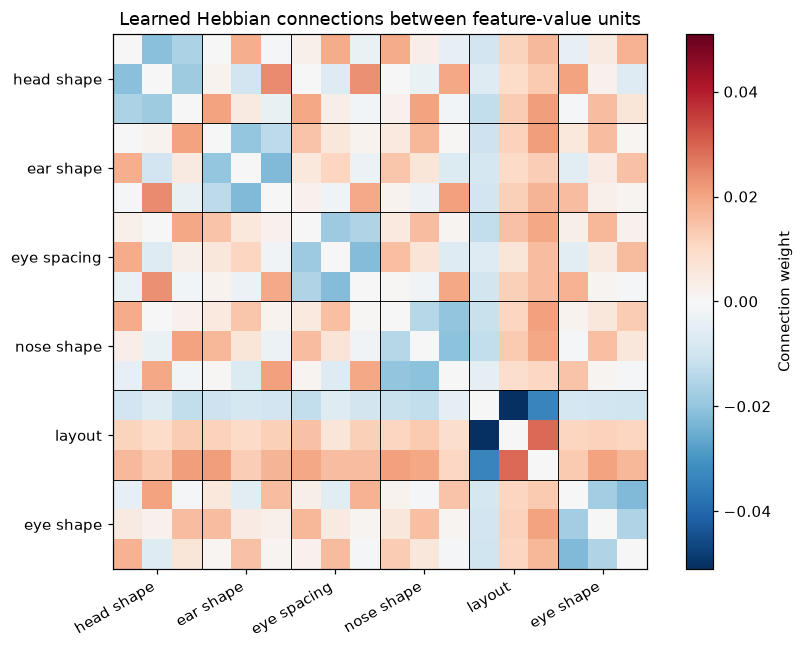

In [3]:
assert np.allclose(memory.weights, memory.weights.T)
assert np.all(np.diag(memory.weights) == 0)
priors = {"uniform": kernel_bank.logpriors['uniform'],
          "kernel exemplar": kernel_bank.logpriors['exemplar'],
          "Hopfield energy": hopfield_bank.logpriors['exemplar']}
for name, logprior in priors.items():
    print(name, "entropy", round(float(entropy(np.exp(logprior))), 3),
          "effective candidate count", round(float(np.exp(entropy(np.exp(logprior)))), 1))
print("Energy range:", memory.energy(library.states).min(), memory.energy(library.states).max())

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(memory.weights, cmap='RdBu_r',
                   vmin=-np.abs(memory.weights).max(), vmax=np.abs(memory.weights).max())
for boundary in memory.offsets[1:-1]:
    ax.axhline(boundary-.5, color='black', lw=.6)
    ax.axvline(boundary-.5, color='black', lw=.6)
ticks = (memory.offsets[:-1]+memory.offsets[1:]-1)/2
ax.set_xticks(ticks, FACTOR_NAMES, rotation=30, ha='right')
ax.set_yticks(ticks, FACTOR_NAMES)
ax.set_title("Learned Hebbian connections between feature-value units")
fig.colorbar(image, ax=ax, label="Connection weight")
fig.tight_layout(); fig.savefig(OUT / 'connections.png', dpi=160); plt.show()

## Held-out image completion

The same noisy visible pixels and known masks feed both exemplar priors. Full-candidate inference combines each prior with the original pixel or VSA image-evidence score. The truth enters evaluation after prediction. A posterior mean averages complete candidate drawings. No category or feature cue is supplied for this image-completion comparison.

We measure hidden Brier score, hidden stroke recall, and hidden-background false-positive rate. Sparse line drawings can make a blank hidden region look good under Brier score, so the copy-fragments control is included. The benchmark is exploratory and uses the same 27 trials for every condition.

uniform {'hidden_brier': 0.01448, 'hidden_recall': 0.8277, 'hidden_false_positive': 0.00381}
kernel exemplar {'hidden_brier': 0.01409, 'hidden_recall': 0.85786, 'hidden_false_positive': 0.00839}
Hopfield energy {'hidden_brier': 0.01378, 'hidden_recall': 0.83845, 'hidden_false_positive': 0.00519}


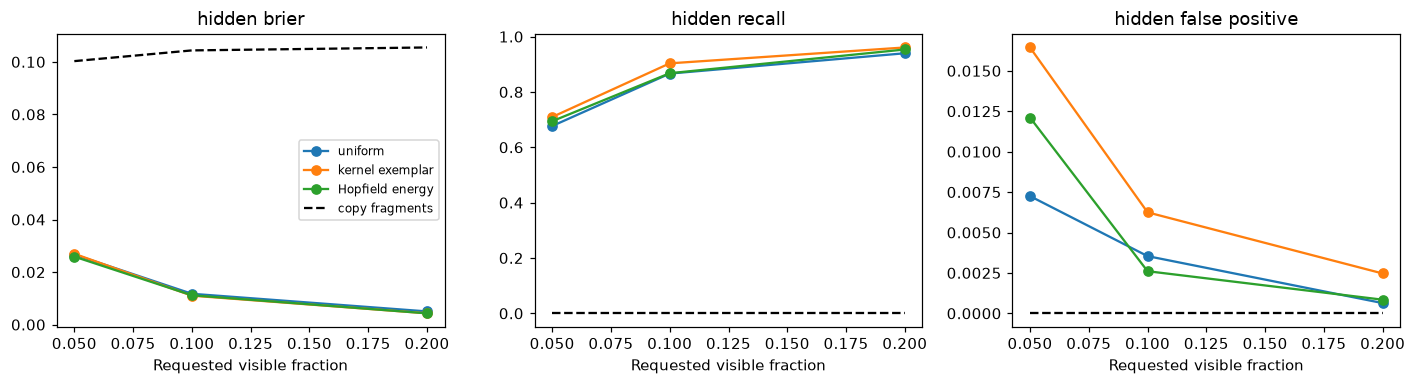

In [4]:
encoder = PixelVSA(IMAGE_SIZE, VSA_DIM, seed=SEED+10)
trials = sample_trials(library, TRIALS_PER_VISIBILITY, VISIBILITIES,
                       seed=SEED+100, flip_probability=FLIP_PROBABILITY)
image_rows = []
for trial_id, trial in enumerate(trials):
    copy_metrics = completion_metrics(trial['observed'], trial['truth'], trial['observed'], trial['mask'])
    image_rows.append(dict(trial=trial_id, visibility=trial['visibility'], backend='copy',
                           prior='copy fragments', **copy_metrics))
    for backend in ('pixels', 'vsa'):
        ll = encoder.evidence_scores(library.images, trial['observed'], trial['mask'],
                                     FLIP_PROBABILITY, backend)
        for name, logprior in priors.items():
            q = posterior(ll, logprior, PRIOR_STRENGTH)
            metrics = completion_metrics(prediction(q, library.images), trial['truth'],
                                          trial['observed'], trial['mask'])
            image_rows.append(dict(trial=trial_id, visibility=trial['visibility'],
                                   backend=backend, prior=name, **metrics))
with (OUT / 'image_completion.csv').open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(image_rows[0]))
    writer.writeheader(); writer.writerows(image_rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric in zip(axes, ('hidden_brier','hidden_recall','hidden_false_positive')):
    for name in priors:
        values = [np.mean([r[metric] for r in image_rows if r['backend']=='vsa' and
                          r['prior']==name and r['visibility']==v]) for v in VISIBILITIES]
        ax.plot(VISIBILITIES, values, 'o-', label=name)
    baseline = [np.mean([r[metric] for r in image_rows if r['backend']=='copy' and
                         r['visibility']==v]) for v in VISIBILITIES]
    ax.plot(VISIBILITIES, baseline, 'k--', label='copy fragments')
    ax.set(xlabel='Requested visible fraction', title=metric.replace('_',' '))
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / 'image_metrics.png', dpi=160); plt.show()
for name in priors:
    selected = [r for r in image_rows if r['backend']=='vsa' and r['prior']==name]
    print(name, {m:round(float(np.mean([r[m] for r in selected])), 5)
                 for m in ('hidden_brier','hidden_recall','hidden_false_positive')})

uniform dense mean-field TV from full-candidate result: 0.5857
kernel exemplar dense mean-field TV from full-candidate result: 0.2025
Hopfield energy dense mean-field TV from full-candidate result: 0.2603


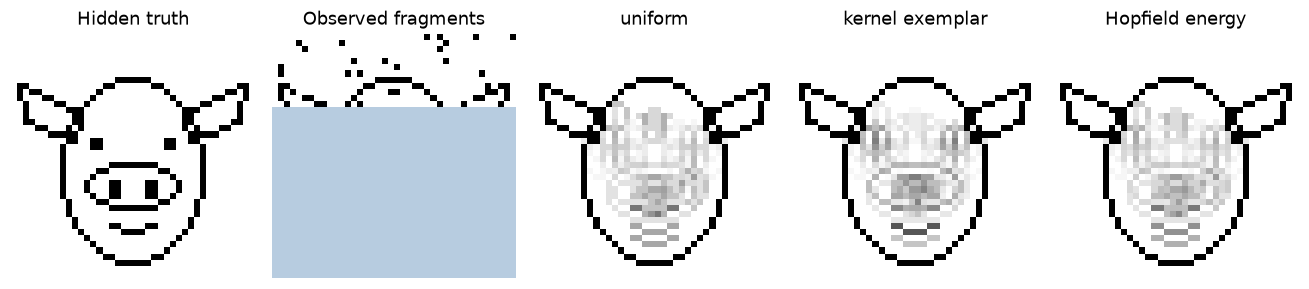

In [5]:
demo_id = int(library.test_ids[np.argmax(library.teacher_logp[0, library.test_ids])])
truth = library.images[demo_id]
mask = np.broadcast_to(np.arange(IMAGE_SIZE)[:,None] < round(.3*IMAGE_SIZE), truth.shape).copy()
observed = observe(truth, mask, FLIP_PROBABILITY, np.random.default_rng(37))
ll = encoder.evidence_scores(library.images, observed, mask, FLIP_PROBABILITY, 'vsa')
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
show_completion(axes[0], truth, 'Hidden truth')
show_observation(axes[1], observed, mask)
for ax, (name, logprior) in zip(axes[2:], priors.items()):
    q = posterior(ll, logprior, PRIOR_STRENGTH)
    show_completion(ax, prediction(q, library.images), name)
    approximate = mean_field(ll, logprior, library.states, CARDINALITIES,
                             strength=PRIOR_STRENGTH, sweeps=25, seed=7)
    print(name, 'dense mean-field TV from full-candidate result:',
          round(float(.5*np.abs(approximate['joint']-q).sum()), 4))
fig.tight_layout(); fig.savefig(OUT / 'image_comparison.png', dpi=160); plt.show()

## Recurrent retrieval from partial feature cues

This separate memory task supplies known feature values directly and marks unknown features with $-1$. Unknown groups start with random values. There is no image-evidence term in this controlled retrieval task.

On each asynchronous update, the network chooses the value of a free feature group that lowers the full energy. Known groups stay clamped. Ties retain the current value. Each strict update decreases energy, and the routine reports convergence when a sweep changes nothing. The endpoint is a local minimum over free single-feature changes.

$$
z_j\leftarrow\underset{v}{\operatorname{argmin}}\ E(z_1,\ldots,z_{j-1},v,z_{j+1},\ldots).
$$

For the same cue, exhaustive search gives a global minimum-energy reference and the kernel prior gives a MAP reference. Retrieval can reach a correct target, another stored configuration, or an unseen combination. An unseen combination can be correct for a held-out target. Outcomes below distinguish those cases.


 stored
random initialization {'hidden_feature_accuracy': 0.315, 'exact_target': 0.056, 'wrong_stored_configuration': 0.222, 'wrong_unseen_combination': 0.722, 'correct_unseen_combination': 0.0}
kernel MAP {'hidden_feature_accuracy': 0.519, 'exact_target': 0.278, 'wrong_stored_configuration': 0.667, 'wrong_unseen_combination': 0.056, 'correct_unseen_combination': 0.0}
global minimum energy {'hidden_feature_accuracy': 0.5, 'exact_target': 0.222, 'wrong_stored_configuration': 0.556, 'wrong_unseen_combination': 0.222, 'correct_unseen_combination': 0.0}
recurrent retrieval {'hidden_feature_accuracy': 0.426, 'exact_target': 0.222, 'wrong_stored_configuration': 0.556, 'wrong_unseen_combination': 0.222, 'correct_unseen_combination': 0.0}

 held-out
random initialization {'hidden_feature_accuracy': 0.315, 'exact_target': 0.167, 'wrong_stored_configuration': 0.333, 'wrong_unseen_combination': 0.5, 'correct_unseen_combination': 0.167}
kernel MAP {'hidden_feature_accuracy': 0.333, 'exact_target'

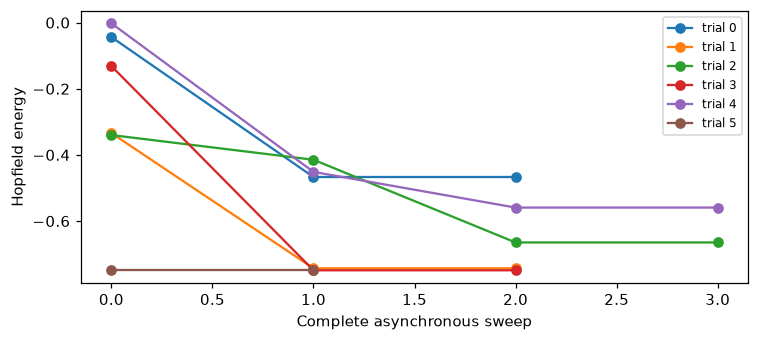

In [6]:
rng = np.random.default_rng(SEED+300)
retrieval_results = []
retrieval_rows = []
energies = memory.energy(library.states)
for split, pool in (('stored', np.unique(training_ids)), ('held-out', library.test_ids)):
    target_ids = rng.choice(pool, RETRIEVAL_TRIALS_PER_SPLIT, replace=True)
    for trial_id, target_id in enumerate(target_ids):
        target = library.states[target_id]
        known = np.zeros(len(CARDINALITIES), dtype=bool)
        known[rng.choice(len(CARDINALITIES), N_KNOWN_FEATURES, replace=False)] = True
        cue = np.where(known, target, -1)
        result = memory.retrieve(cue, max_sweeps=MAX_RETRIEVAL_SWEEPS,
                                  random_order=RANDOM_UPDATE_ORDER, seed=SEED+trial_id)
        assert np.all(result['state_trace'][:, known] == target[known])
        assert np.all(np.diff(result['energy_trace']) <= 1e-10)
        allowed = np.all(library.states[:, known] == target[known], axis=1)
        global_id = int(np.argmin(np.where(allowed, energies, np.inf)))
        kernel_id = int(np.argmax(np.where(allowed, priors['kernel exemplar'], -np.inf)))
        predictions = {'random initialization':result['initial_state'],
                       'kernel MAP':library.states[kernel_id],
                       'global minimum energy':library.states[global_id],
                       'recurrent retrieval':result['state']}
        for method, state in predictions.items():
            exact = bool(np.array_equal(state, target))
            stored = tuple(state) in stored_patterns
            retrieval_rows.append(dict(split=split, trial=trial_id, method=method,
                hidden_feature_accuracy=float(np.mean(state[~known] == target[~known])),
                exact_target=exact, wrong_stored_configuration=stored and not exact,
                wrong_unseen_combination=not stored and not exact,
                correct_unseen_combination=not stored and exact))
        gap = float(result['energy_trace'][-1]-energies[global_id])
        assert gap >= -1e-10
        retrieval_results.append(dict(split=split, target=target.copy(), known=known,
            result=result, global_state=library.states[global_id].copy(), global_energy_gap=gap))

with (OUT / 'feature_retrieval.csv').open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(retrieval_rows[0]))
    writer.writeheader(); writer.writerows(retrieval_rows)
for split in ('stored', 'held-out'):
    print('\n',split)
    for method in predictions:
        selected = [r for r in retrieval_rows if r['split']==split and r['method']==method]
        print(method, {m:round(float(np.mean([r[m] for r in selected])), 3)
              for m in ('hidden_feature_accuracy','exact_target','wrong_stored_configuration',
                        'wrong_unseen_combination','correct_unseen_combination')})

fig, ax = plt.subplots(figsize=(7, 3.2))
for i, row in enumerate(retrieval_results[:6]):
    ax.plot(row['result']['energy_trace'], 'o-', label=f'trial {i}')
ax.set(xlabel='Complete asynchronous sweep', ylabel='Hopfield energy')
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(OUT / 'retrieval_energy.png', dpi=160); plt.show()
print('Converged fraction:', np.mean([r['result']['converged'] for r in retrieval_results]))
print('Fraction above the global minimum:', np.mean([r['global_energy_gap']>1e-10 for r in retrieval_results]))

## One retrieval and dependence on initialization

The first held-out feature-cue trial is preselected for illustration. The random initialization fills unknown features with guesses, so its rendered image includes those guesses. Repeat retrieval under the same clamped cue and several random initializations to inspect distinct attractors. The hidden target appears only in evaluation.

Clamped features: {'head shape': 'tall', 'eye spacing': 'medium', 'nose shape': 'triangle'}
Endpoints from eight initializations: {(np.int64(2), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(2)): 8}
Saved figures, paired results and learned weights to C:\NEU_172L\vsa_gestalt_closure_hebbian\outputs\hopfield


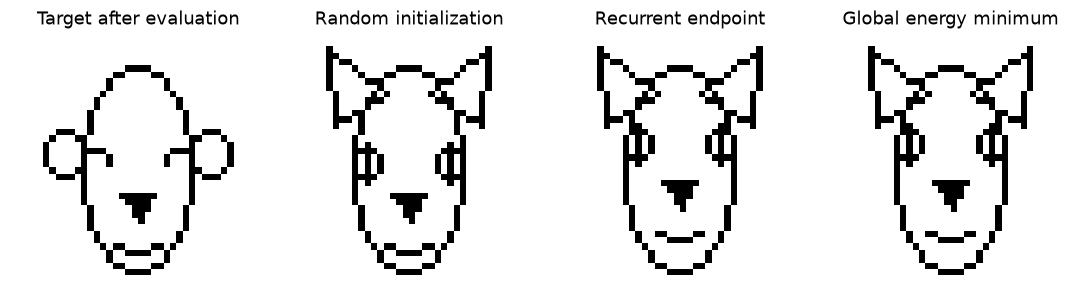

In [7]:
example = next(r for r in retrieval_results if r['split']=='held-out')
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, title, state in zip(axes,
        ('Target after evaluation','Random initialization','Recurrent endpoint','Global energy minimum'),
        (example['target'],example['result']['initial_state'],example['result']['state'],example['global_state'])):
    show_completion(ax, render_state(state, IMAGE_SIZE), title)
fig.tight_layout(); fig.savefig(OUT / 'feature_retrieval_example.png', dpi=160); plt.show()
print('Clamped features:', {FACTOR_NAMES[j]:FACTOR_VALUES[j][example['target'][j]]
                            for j in np.flatnonzero(example['known'])})
cue = np.where(example['known'], example['target'], -1)
endpoints = {}
for initialization_seed in range(8):
    result = memory.retrieve(cue, seed=initialization_seed, random_order=RANDOM_UPDATE_ORDER,
                              max_sweeps=MAX_RETRIEVAL_SWEEPS)
    state = tuple(result['state'])
    endpoints[state] = endpoints.get(state, 0)+1
print('Endpoints from eight initializations:', endpoints)

summary = dict(training_draws=len(training_ids), distinct_training_configurations=len(stored_patterns),
               bipolar_units=memory.n_bits, inverse_temperature=HOPFIELD_BETA,
               image_trials=len(trials), feature_trials=len(retrieval_results),
               known_features=N_KNOWN_FEATURES,
               retrieval_converged_fraction=float(np.mean([r['result']['converged'] for r in retrieval_results])),
               above_global_minimum_fraction=float(np.mean([r['global_energy_gap']>1e-10 for r in retrieval_results])),
               image_metrics={name:{metric:float(np.mean([r[metric] for r in image_rows
                             if r['backend']=='vsa' and r['prior']==name]))
                             for metric in ('hidden_brier','hidden_recall','hidden_false_positive')}
                             for name in priors})
(OUT / 'comparison_summary.json').write_text(json.dumps(summary, indent=2))
np.savez(OUT / 'learned_weights.npz', weights=memory.weights,
          cardinalities=np.array(CARDINALITIES), training_ids=training_ids)
print('Saved figures, paired results and learned weights to', OUT)

## Reading the comparisons

The energy prior supplies a learned preference over whole feature configurations. Image completion combines that preference with pixel-derived evidence, using either full-candidate or mean-field inference. Recurrent retrieval separately seeks a local energy minimum under explicit feature constraints.

The existing kernel exemplar prior remains the reference. Lower energy or successful convergence alone does not establish target recovery. Inspect incorrect stored configurations, incorrect unseen combinations, and correct held-out combinations alongside hidden stroke recall and invented contours.

The default energy gain is a fixed exploratory setting. Its entropy can differ substantially from the kernel prior. The memory learns correlations among supplied features and keeps the VSA codebooks fixed. The renderer and feature vocabulary remain the same as in the previous experiments.